# 22 — Research Roadmap and Experiment Synthesis

This notebook is a research decision document. It trains no model, creates no feature, and writes no submission.
It synthesizes Notebooks 01–21 using repository artifacts, immutable submission checks, and explicitly supplied
leaderboard records.

## Frozen prioritization policy

Weights are fixed before inspecting the priority ranking: evidence 25%, expected leaderboard impact 20%,
robustness 20%, reproducibility 10%, innovation/practicality 10%, low leakage risk 5%, low overfitting risk 5%,
and low computational cost 5%. Missing public results remain `not available`; local RMSE is never converted into
an invented public score.

## Evidence inventory, leaderboard history, taxonomy and roadmap

The executable cell validates the canonical artifact, inventories every numbered notebook file (including both
distinct Notebook 11 files), creates all required CSV/Markdown artifacts and the public-score plot, then verifies
that the two existing submission files still exist and the canonical SHA is unchanged.

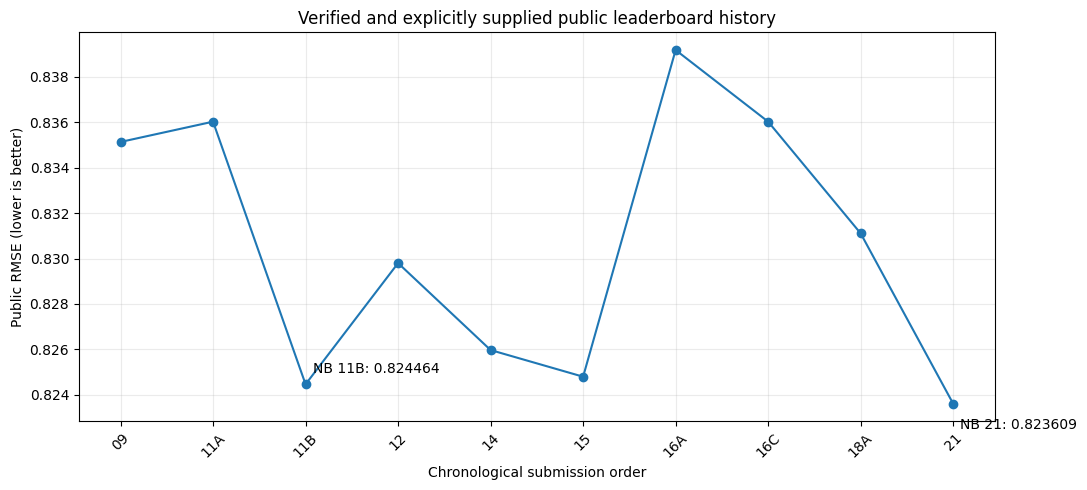

,Idea,Evidence strength,Expected leaderboard impact,Robustness potential,Reproducibility,Innovation/practicality,Low leakage risk,Low overfitting risk,Low computational cost,Weighted priority score,Rank,Weights
0,Correction transferability across dates,5,3,5,5,4,5,4,3,4.35,1,"{""Evidence strength"": 0.25, ""Expected leaderbo..."
3,Southern hemisphere targeted correction,5,3,4,5,4,5,4,5,4.25,2,"{""Evidence strength"": 0.25, ""Expected leaderbo..."
1,Correction uncertainty weighting,4,3,5,5,4,5,4,5,4.20,3,"{""Evidence strength"": 0.25, ""Expected leaderbo..."
2,Fold-stability-weighted correction,4,3,5,5,4,5,4,5,4.20,3,"{""Evidence strength"": 0.25, ""Expected leaderbo..."
8,Residual calibration without target leakage,4,3,5,5,4,5,4,3,4.10,5,"{""Evidence strength"": 0.25, ""Expected leaderbo..."
4,Test-vs-train spatial support analysis,4,2,4,5,4,5,5,5,3.85,6,"{""Evidence strength"": 0.25, ""Expected leaderbo..."
5,Latitude + climate hierarchy,3,3,4,4,4,5,3,5,3.60,7,"{""Evidence strength"": 0.25, ""Expected leaderbo..."
6,Multi-resolution spatial correction,3,3,4,4,4,5,3,3,3.50,8,"{""Evidence strength"": 0.25, ""Expected leaderbo..."
7,Conservative correction ensemble,3,2,3,4,3,5,3,5,3.10,9,"{""Evidence strength"": 0.25, ""Expected leaderbo..."
9,New main model family,1,2,2,3,2,4,1,1,1.85,10,"{""Evidence strength"": 0.25, ""Expected leaderbo..."


# Final research roadmap

## Current best system definition

- **Canonical base:** Notebook 11 final selected blend, public RMSE 0.824463818.
- **Base components:** known-row LightGBM expert; masked base LightGBM plus causal-history expert conservative blend.
- **Refinement:** Notebook 21 stable hemisphere residual intercept, learned from older OOF residuals, shrinkage/cap controlled.
- **Application:** known rows unchanged; only masked rows with stable evidence are corrected.
- **Joint gates:** spatial mean and south improve; strict temporal, irregular, space-time and worst fold remain within predeclared tolerances; correction magnitude and support pass safety checks.
- **Integrity:** rows 280961, ID order retained, no duplicate/NaN/inf.
- **Correlation vs base:** 0.999512715393; MAD 0.006554646374; max difference 0.050000000000; changed fraction 13.109293%.
- **SHA256:** canonical `b61ecd15862ca6d7527c4f494de802ed6ea6d31c420737cb78f977d9bda3b968`; refined `84d4ce6efdbfc3fbca55d9eea1ebccfe628ffa962e31b62a654c179dc649b488`.

Notebook 21 is the **current best refined submission**, not a replacement name for the canonical base.


## Evidence synthesis

1. **Most successful main model:** Notebook 11 canonical LightGBM selected blend.
2. **Most successful refinement:** Notebook 21 small, stable hemisphere residual correction.
3. **Strongest local–public mismatch explanation:** validation mismatch plus repeated local-selection overfit under temporal/spatial distribution shift; specific mechanisms remain hypotheses except proven pipeline/leakage audits.
4. **Primary decision support:** joint strict temporal + irregular hindcast + spatial block + space-time gates, with spatial evidence weighted but never used alone.
5. **Never standalone:** Notebook 08 same-date row split, Notebook 11 local metric, or spatial ranking proxy alone.
6. **Critical leakage risk:** location-major `prior_global_month` ordering used future-timestamp training targets in 91.30% of rows. Notebook 20 did not find direct validation-target leakage.
7. **Current best:** Notebook 11 canonical base refined by Notebook 21; public RMSE 0.823609466.
8. **Do not repeat:** broad boosting/tuning/feature searches, uncontrolled blends, risky target encodings, single-metric selection, or unreproduced-base experiments.
9. **Highest priority:** frozen correction transferability across dates.
10. **Order:** NB23 transferability → NB24 uncertainty weighting if confirmed → NB25 spatial-support eligibility audit.
11. **Stop:** apply `research_stopping_rules.md`; especially stop a family after two public-worse submissions or failed independent sign/worst-fold replication.
12. **Strongest technical story:** a strong canonical boosting system survived extensive alternatives; audits exposed validation and reproducibility weaknesses; a bounded, OOF-derived spatial bias correction—rather than a new large model—produced the only verified improvement. This is the best supported explanation, not proof of causality.

## What actually worked

- **NB11:** score improvement; reusable frozen selected-blend base.
- **NB17:** methodology correction; reusable artifact identity/SHA gate.
- **NB19:** specification correction; reusable availability and robustness contract.
- **NB20:** validation correction; reusable joint temporal/spatial gate suite.
- **NB21:** score improvement; reusable bounded OOF residual correction policy.

The hypothesis that NB21 won because the main model was already strong and the residual correction removed a small,
stable spatial bias is consistent with its high base correlation, small MAD, known-row invariance, southern validation
gain and improved public score. It remains the strongest repository-supported explanation, not an experimentally proven causal fact.

## Public-score caveat

Notebook 16 A/C scores were explicitly supplied for this synthesis but exact score strings were not found in repository
artefacts; the leaderboard table flags this rather than presenting them as independently corroborated.


All required Notebook 22 artifacts created; no submission was written.


In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "notebooks").exists():
    ROOT = ROOT.parent
ART = ROOT / "artifacts/notebook22"
ART.mkdir(parents=True, exist_ok=True)
CANON = ROOT / "submissions/submission_optimized.csv"
BEST = ROOT / "submissions/submission_21_spatial_residual_candidate.csv"
EXPECTED_CANON_SHA = "b61ecd15862ca6d7527c4f494de802ed6ea6d31c420737cb78f977d9bda3b968"


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


assert sha(CANON) == EXPECTED_CANON_SHA
assert BEST.exists()
nb_files = sorted(p for p in (ROOT / "notebooks").glob("[0-2][0-9]_*.ipynb") if int(p.name[:2]) <= 21)
assert {f"{n:02d}" for n in range(1, 22)} <= {p.name[:2] for p in nb_files}

# Evidence-first inventory. Missing public values remain NaN, never inferred from local RMSE.
rows = [
("01","01_eda.ipynb","Data/schema and target exploration","descriptive statistics","data understanding","none","not available",np.nan,False,"methodological/audit notebook","Established structure and missingness; no model claim.","No"),
("02","02_baseline_model.ipynb","Establish simple prediction baseline","baseline regressors","main model","random split","not available",np.nan,True,"inconclusive","Baseline reference, but early validation is not decision-grade.","Only as sanity check"),
("03","03_lightgbm.ipynb","Test LightGBM","LightGBM","model family","early validation","not available",np.nan,True,"promising but unconfirmed","Boosting became the strongest model family.","Only through frozen canonical"),
("04","04_xgboost.ipynb","Test XGBoost","XGBoost","model family","early validation","not available",np.nan,True,"failed","No verified public advantage over LightGBM.","No without new evidence"),
("05","05_catboost.ipynb","Test CatBoost","CatBoost","model family","early validation","not available",np.nan,True,"failed","No verified public advantage.","No without new evidence"),
("06","06_ensemble.ipynb","Blend boosting predictions","ensemble","blend","early validation","not available",np.nan,True,"inconclusive","Blends require OOF and drift controls.","Only conservatively"),
("07","07_feature_engineering.ipynb","General feature engineering","engineered features","feature set","early validation","not available",np.nan,True,"locally improved but public worse","Large feature expansion did not establish public gain.","No broad expansion"),
("08","08_time_series_validation.ipynb","Temporal validation redesign","date-aware validation","validation","mixed temporal folds","0.6109 recorded",np.nan,False,"methodological/audit notebook","Same-month row splitting remained optimistic/leaky for spatially repeated dates.","No; replace"),
("09","09_advanced_model_selection.ipynb","Advanced model selection and submission","boosting/model selection","model and selection","temporal validation","not available",0.835133802,True,"promising but unconfirmed","Produced the pre-Notebook-11 reference system.","Historical reference"),
("10","10_model_explainability.ipynb","Explain strongest model and residuals","importance/residual analysis","diagnostics","same as 09","not available",np.nan,False,"methodological/audit notebook","Exposed spatial, temporal and masked weaknesses.","Yes as diagnostic"),
("11A","11_submission_improvement.ipynb","Dual-expert submission improvement","two LightGBM experts","expert split","temporal validation","not available",0.836026816,True,"locally improved but public worse","A distinct Notebook 11 file; its recorded 0.836026816 is not the canonical selected blend.","No"),
("11B","11_submission_optimization.ipynb","Optimize submission with conservative blend","LightGBM base + causal-prior expert","masked blend","temporal OOF","0.711647 overall; 0.758030 masked",0.824463818,True,"successful","Canonical selected blend produced the durable public baseline.","Yes, frozen base"),
("12","12_advanced_submission_optimization.ipynb","Expand optimization ideas","advanced features/blends","feature and post-processing","temporal OOF","local improved; exact selected value in notebook",0.8298,True,"locally improved but public worse","Large local gain did not transfer; likely validation overfit/distribution mismatch.","No"),
("13","13_generalization_optimization.ipynb","Reduce local overfitting","pruning/regularization/OOF analysis","complexity and regularization","robust temporal OOF","not available",np.nan,True,"inconclusive","Shifted objective toward robustness; no verified public best.","Use principles only"),
("14","14_alternative_models.ipynb","Test non-boosting families","alternative regressors/voting/stacking","model family","temporal OOF","0.688811 recorded representative",0.825971129,True,"locally improved but public worse","Better local ranking did not beat canonical public.","No broad retest"),
("15","15_delta_spatiotemporal_forecasting.ipynb","Forecast target delta with dual experts","delta LightGBM","target formulation","temporal OOF","0.694090 recorded representative",0.824797753,True,"promising but unconfirmed","Nearly canonical public but did not improve it.","Only with new causal evidence"),
("16","16_competition_level_feature_research.ipynb","Large single-feature and interaction research","feature ablations/clusters/encodings","feature set","Notebook-11-like OOF","best tables in artifacts/notebook16",0.839181712,True,"locally improved but public worse","Best-single submission generalized poorly; broad feature search overfit local selection.","No broad search"),
("16C","16 C submission from Notebook 16","Claimed Notebook-11 diverse reproduction","blend/cascade","pipeline identity","Notebook-16 OOF","not available",0.836026816,True,"failed","Notebook 17 proved it was not the actual Notebook 11 selected-blend pipeline.","No"),
("17","17_submission_reproducibility_audit.ipynb","Audit submission identity and reproducibility","hash/file/pipeline comparison","reproducibility","artifact comparison","exact reproduction",np.nan,False,"methodological/audit notebook","Recovered immutable canonical identity and exposed raw-baseline/selected-blend confusion.","Yes, mandatory gate"),
("18","18_domain_hydrology_feature_research.ipynb","Test hydrology-inspired features","domain feature ablation","feature set","canonical OOF","0.709586 recorded representative",0.831108253,True,"locally improved but public worse","Physical labels alone did not add independent predictive signal.","No broad retest"),
("19","19_challenge_technical_specification.ipynb","Translate challenge into technical specification","availability/leakage/physics audit","problem specification","methodological","not applicable",np.nan,False,"methodological/audit notebook","Aligned research with prediction-time availability and space-time robustness.","Yes, design contract"),
("20","20_strict_temporal_spatial_validation.ipynb","Audit leakage and generalization proxies","strict temporal/irregular/spatial/space-time","validation and priors","four strict systems","0.740524 / 0.680366 / 0.801398 / 0.817423",np.nan,False,"methodological/audit notebook","Found prior ordering risk and southern spatial weakness; strict priors did not pass all gates.","Yes, decision support"),
("21","21_spatial_residual_correction.ipynb","Correct stable spatial residual bias","small hemisphere residual intercept","masked prediction refinement","all four strict systems","spatial gain 0.00531118",0.823609466,True,"successful","Small evidence-gated correction delivered the first verified public improvement over canonical.","Yes, frozen refinement"),
]
cols=["Notebook number","Notebook name","Main purpose","Model or method","Main component changed",
      "Validation","Local metric","Public RMSE","Submission produced","Result category","Main takeaway","Retry?"]
inventory=pd.DataFrame(rows,columns=cols)
inventory["Public difference vs canonical"]=inventory["Public RMSE"]-0.824463818
inventory.to_csv(ART/"experiment_inventory.csv",index=False)

history_rows=[
("09","submission filename not available","advanced model selection",0.835133802,"repository notebook record"),
("11A","submission filename not available","dual-expert improvement",0.836026816,"repository notebook record"),
("11B","submission_optimized.csv","canonical selected blend",0.824463818,"repository artifact + SHA audit"),
("12","submission filename not available","advanced optimization",0.8298,"repository notebook/user-recorded result"),
("14","submission_14.csv","alternative-model blend",0.825971129,"artifacts/notebook20"),
("15","submission filename not available","delta target",0.824797753,"artifacts/notebook20"),
("16A","submission_16_A_best_single.csv","best single feature",0.839181712,"task-provided; in-repo score corroboration unavailable"),
("16C","submission_16_C_notebook11_diverse.csv","non-identical Notebook-11 diverse pipeline",0.836026816,"task-provided; in-repo score corroboration unavailable"),
("18A","submission_18_A_domain_best.csv","drying-transition domain feature",0.831108253,"artifacts/notebook20"),
("21","submission_21_spatial_residual_candidate.csv","stable hemisphere residual correction",0.823609466,"task-provided current public result"),
]
history=pd.DataFrame(history_rows,columns=["Notebook","Submission filename","Method","Public RMSE","Evidence source"])
best=np.inf; prev=[]; new=[]
for score in history["Public RMSE"]:
    prev.append(np.nan if np.isinf(best) else score-best)
    new.append(score<best)
    best=min(best,score)
history["Difference vs previous best"]=prev
history["New best"]=new
alignment={"09":"not available","11A":"not available","11B":"yes","12":"no","14":"no","15":"no",
           "16A":"no","16C":"no","18A":"no","21":"yes"}
history["Aligned with local expectation"]=history.Notebook.map(alignment)
history.to_csv(ART/"public_leaderboard_history.csv",index=False)

plt.figure(figsize=(11,5))
plt.plot(np.arange(1,len(history)+1),history["Public RMSE"],marker="o",lw=1.5)
for i,r in history.iterrows():
    if r.Notebook in ["11B","21"]:
        plt.annotate(f"NB {r.Notebook}: {r['Public RMSE']:.6f}",(i+1,r["Public RMSE"]),
                     xytext=(5,-18 if r.Notebook=="21" else 8),textcoords="offset points")
plt.xticks(np.arange(1,len(history)+1),history.Notebook,rotation=45)
plt.ylabel("Public RMSE (lower is better)"); plt.xlabel("Chronological submission order")
plt.title("Verified and explicitly supplied public leaderboard history")
plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(ART/"public_leaderboard_history.png",dpi=150); plt.show()

taxonomy_data=[
("Baseline/statistical","01,02",2,"not available","not available","weak validation / limited capacity","reference only","Low"),
("Gradient boosting","03,04,05,09,11",5,"0.711647 (NB11 recorded)","0.824463818","redundancy and validation mismatch","strongest main-model family","High as frozen base"),
("Ensemble/blending","06,11,12,14,16",5,"various; not directly comparable","0.824463818","prediction drift / OOF selection overfit","works only conservatively","Medium"),
("Feature engineering","07,12,16",3,"local gains recorded","0.8298","multiple-testing and distribution shift","poor broad-search transfer","Low"),
("Time-series validation","08,11,20",3,"0.6109/0.711647/strict suite","not applicable","same-date contamination or incomplete space test","methodological value high","High"),
("Alternative models","14",1,"0.688811 representative","0.825971129","local-public rank mismatch","did not beat LightGBM","Low"),
("Delta forecasting","15",1,"0.694090 representative","0.824797753","target-form mismatch/instability (hypothesis)","near-best but unconfirmed","Medium-low"),
("Hydrology-inspired features","18",1,"0.709586 representative","0.831108253","weak incremental representation","poor public transfer","Low"),
("Reproducibility audit","17",1,"exact artifact match","not applicable","pipeline identity ambiguity","essential control","High"),
("Challenge specification analysis","19",1,"not applicable","not applicable","none; decision document","essential design alignment","High"),
("Leakage/validation audit","20",1,"strict 0.740524; spatial 0.801398","not applicable","limited candidate count","essential but proxy uncertain","High"),
("Spatial residual correction","21",1,"spatial gain 0.00531118","0.823609466","transfer stability remains limited evidence","positive public transfer","High"),
]
taxonomy=pd.DataFrame(taxonomy_data,columns=["Approach","Notebooks","Experiment count","Best local result",
 "Best public result","Typical failure reason","Public generalization tendency","Future research value"])
taxonomy.to_csv(ART/"approach_taxonomy.csv",index=False)

failure_data=[
("New boosting models","04,05,09","No verified gain over canonical","model redundancy; validation mismatch","hypothesis"),
("Alternative models","14","Local representative improved but public 0.825971129","validation mismatch / model redundancy","observed mismatch; cause hypothesis"),
("Large feature engineering","12,16","Public 0.8298, 0.839181712","multiple-testing overfit; distribution shift","observed public loss; cause hypothesis"),
("Domain hydrology features","18","Public 0.831108253","weak independent physical representation","observed; mechanism hypothesis"),
("Delta forecasting","15","Public 0.824797753","temporal/spatial instability or target noise","observed small loss; cause hypothesis"),
("Large blend/cascade changes","12,16C","Public loss and identity mismatch","prediction drift / pipeline mismatch","partly proven by NB17"),
("Strict prior alternatives","20","No variant passed every gate","loss of risky training-feature advantage and weaker fit","gate failure observed; cause hypothesis"),
]
failure=pd.DataFrame(failure_data,columns=["Failure family","Evidence notebooks","Observed result","Possible cause","Evidence status"])
failure.to_csv(ART/"failure_modes.csv",index=False)

validation_rows=[
("Notebook 08 validation","0.6109 recorded","Not decision-grade","Rows from the same date can enter train and validation; spatial peers reveal contemporaneous state."),
("Notebook 11 temporal OOF","0.711647 overall; 0.758030 masked","Useful but incomplete","Date grouping and known/masked simulation are useful; spatial transfer and irregular test gaps are incomplete."),
("Strict temporal","0.740524 canonical mean","Required joint gate","Forecast-origin causality; does not alone measure unseen-region transfer."),
("Irregular-date hindcast","0.680366 canonical mean","Required joint gate","Better imitates official non-uniform date offsets."),
("Spatial block","0.801398 canonical mean; worst south 0.833364","Required joint gate, not standalone","Measures contiguous-region transfer; strongest observed public rank proxy."),
("Space-time","0.817423 canonical","Required joint gate","Measures simultaneous future-date and held-region transfer."),
("Public ranking proxy","Spearman 0.40; pairwise 66.7%","Weak evidence","Highest among NB20 systems, but only four candidates and partially non-common historical OOF evidence."),
]
validation_lessons=pd.DataFrame(validation_rows,columns=["Validation system","Verified result","Recommended role","Lesson"])
validation_lessons.to_csv(ART/"validation_lessons.csv",index=False)

leakage_rows=[
("Notebook 16 C was not Notebook 11","16C/17","high","No","No","Misidentified candidate and poor public score","Compare code, predictions and artifact hashes","resolved by NB17"),
("Raw baseline vs selected blend confusion","11/16/17","high","No","No","Wrong reference invalidates ablation conclusions","Freeze selected-blend artifact","resolved"),
("prior_global_month location-major ordering","11/20","high","No direct validation-target leakage","Yes","May inflate training representation","Strict time filtering/OOF prior; keep canonical only as immutable base","known, not removed from canonical"),
("91.30% future-timestamp contributor rate","11/20","high","No","Yes","Quantifies training-feature availability risk","Do not use ordering-based expanding feature in new pipelines","confirmed"),
("Validation target not directly included","11/20","medium","No","Potential indirect training-feature issue only","Prevents overstating risk as direct leakage","State distinction explicitly","confirmed"),
("Prediction-time availability","19/20/21","high","No","No if rules followed","Unavailable target/covariate would invalidate method","Use only lat/lon/month and available covariates for correction","controlled"),
("Canonical SHA verification","17/20/21","low","No","No","Protects reproducibility","Assert SHA256 before analysis",f"active: {sha(CANON)}"),
("Metadata-only notebook change","09/worktree audit","low","No","No","Could be mistaken for substantive edit","Preserve and classify separately","observed; untouched"),
]
leakage=pd.DataFrame(leakage_rows,columns=["Risk","Affected notebook/pipeline","Severity","Direct leakage?","Indirect leakage?",
 "Public submission impact","Resolution","Current status"])
leakage.to_csv(ART/"leakage_reproducibility_register.csv",index=False)

dnr_data=[
("New boosting model from scratch","03–05,14","No verified public advantage; redundancy high","Only with new data/target representation evidence"),
("Broad hyperparameter search","12,13,16","Raises local selection overfit","Only nested, frozen multi-system validation"),
("Many generic features","07,12,16","Local gains transferred poorly","Only one justified feature with ablation"),
("Uncontrolled blend/cascade","06,12,16","Creates large prediction drift","Only OOF conservative weights and strict MAD cap"),
("Large prediction correction","21","Success came from bounded refinement","Only if independent transferability evidence supports it"),
("Single-metric optimization","08,11,20","No single proxy captures temporal and spatial shift","Never for final selection"),
("Leakage-risky target encoding","16,20","Ordering/availability risks","Only cross-fitted, cutoff-safe encoding"),
("Assume local gain means public gain","12,14,16,18","Repeated counterexamples","Never; require robust gates"),
("Overwrite canonical artifact","17","Destroys reproducibility","Never"),
("Experiment before reproduction","16C,17","Wrong base invalidates conclusions","Never"),
]
dnr=pd.DataFrame(dnr_data,columns=["Do-not-repeat item","Evidence notebooks","Why","Reconsider only when"])
dnr.to_csv(ART/"do_not_repeat.csv",index=False)

opps=[
("Correction transferability across dates","Repeat frozen NB21 policy on later held-out windows","NB21 public gain; limited temporal evidence",3,"Low","Low","Low","Multiple strict space-time origins","Medium","Medium",4,"High"),
("Correction uncertainty weighting","Scale intercept by bootstrap/stability uncertainty","NB21 stable-bias gate",3,"Low","Low","Low","All four systems + independent window","Low","Medium",4,"High"),
("Fold-stability-weighted correction","Weight correction by sign and magnitude stability","NB21 residual stability table",3,"Low","Low","Low","Nested historical OOF","Low","Medium",3,"High"),
("Southern hemisphere targeted correction","Refine only predeclared southern bias","NB20 worst south; NB21 public gain",3,"Medium","Low","Low","Southern + global strict gates","Low","Low",3,"High"),
("Test-vs-train spatial support analysis","Quantify coverage before correction","NB19 availability; NB21 distribution safety",2,"Low","None","None","Descriptive plus frozen gate","Low","Low",3,"High"),
("Latitude + climate hierarchy","Fallback correction by latitude and climate","NB21 stable latitude; climate alone weak",2,"Medium","Low","Medium","Independent space-time window","Low","Medium",4,"Medium"),
("Multi-resolution spatial correction","Shrink coarse/fine cells hierarchically","NB21 cells show stable bias","2","Medium","Low","Medium","Nested OOF + support minimums","Medium","High",4,"Medium"),
("Conservative correction ensemble","Average only gate-passing corrections","Many NB21 candidates pass","2","Medium","Low","Medium","OOF-only weights; drift cap","Low","Medium",3,"Medium"),
("Residual calibration without target leakage","Cross-fitted calibration using older residuals only","NB20 leakage audit","3","Low","Low","Low","Strict cutoff assertions","Medium","Medium",4,"High"),
("New main model family","Only if correction research saturates","NB14 alternatives failed",1,"High","Low","High","Full nested robust suite","High","High",2,"Low"),
]
opp_cols=["Idea","Technical description","Evidence","Expected impact","Risk","Leakage risk","Prediction drift risk",
          "Validation requirement","Computational cost","Complexity","Novelty","Priority"]
opportunities=pd.DataFrame(opps,columns=opp_cols)

# Weights fixed before scoring: benefits positive; risks/cost converted to 5-score.
weights={"Evidence strength":.25,"Expected leaderboard impact":.20,"Robustness potential":.20,
         "Reproducibility":.10,"Innovation/practicality":.10,"Low leakage risk":.05,
         "Low overfitting risk":.05,"Low computational cost":.05}
score_rows=[
("Correction transferability across dates",5,3,5,5,4,5,4,3),
("Correction uncertainty weighting",4,3,5,5,4,5,4,5),
("Fold-stability-weighted correction",4,3,5,5,4,5,4,5),
("Southern hemisphere targeted correction",5,3,4,5,4,5,4,5),
("Test-vs-train spatial support analysis",4,2,4,5,4,5,5,5),
("Latitude + climate hierarchy",3,3,4,4,4,5,3,5),
("Multi-resolution spatial correction",3,3,4,4,4,5,3,3),
("Conservative correction ensemble",3,2,3,4,3,5,3,5),
("Residual calibration without target leakage",4,3,5,5,4,5,4,3),
("New main model family",1,2,2,3,2,4,1,1),
]
score_cols=["Idea",*weights.keys()]
priorities=pd.DataFrame(score_rows,columns=score_cols)
priorities["Weighted priority score"]=sum(priorities[k]*w for k,w in weights.items())
priorities["Rank"]=priorities["Weighted priority score"].rank(ascending=False,method="min").astype(int)
priorities=priorities.sort_values(["Rank","Idea"])
priorities["Weights"]=json.dumps(weights)
priorities.to_csv(ART/"research_priorities.csv",index=False)
display(priorities)

# Reproducible current-best definition from immutable files and NB21 report.
canon=pd.read_csv(CANON); refined=pd.read_csv(BEST); test=pd.read_csv(ROOT/"data/raw/Test.csv")
delta=refined.Target-canon.Target; known=test.TWS_t.notna()
assert np.array_equal(refined.loc[known,"Target"].to_numpy(),canon.loc[known,"Target"].to_numpy())
current_best=f"""## Current best system definition

- **Canonical base:** Notebook 11 final selected blend, public RMSE 0.824463818.
- **Base components:** known-row LightGBM expert; masked base LightGBM plus causal-history expert conservative blend.
- **Refinement:** Notebook 21 stable hemisphere residual intercept, learned from older OOF residuals, shrinkage/cap controlled.
- **Application:** known rows unchanged; only masked rows with stable evidence are corrected.
- **Joint gates:** spatial mean and south improve; strict temporal, irregular, space-time and worst fold remain within predeclared tolerances; correction magnitude and support pass safety checks.
- **Integrity:** rows 280961, ID order retained, no duplicate/NaN/inf.
- **Correlation vs base:** {np.corrcoef(refined.Target,canon.Target)[0,1]:.12f}; MAD {np.abs(delta).mean():.12f}; max difference {np.abs(delta).max():.12f}; changed fraction {(np.abs(delta)>1e-12).mean():.6%}.
- **SHA256:** canonical `{sha(CANON)}`; refined `{sha(BEST)}`.

Notebook 21 is the **current best refined submission**, not a replacement name for the canonical base.
"""

next_three="""# Next three notebooks

## Notebook 23 — Correction transferability across dates

- **Hypothesis:** the frozen Notebook 21 hemisphere correction retains sign and benefit at multiple later, untouched space-time origins.
- **Why now:** public gain exists, but temporal transfer is the largest remaining uncertainty.
- **Single changed component:** validation origin only; correction policy stays frozen.
- **Gates:** positive median spatial/south gain, strict and irregular loss ≤0.0005, space-time/worst loss ≤0.0002, sign stability ≥75%.
- **Submission:** none unless an untouched final window and all gates pass; at most one.
- **Stop:** stop this family if two independent origins reverse sign or worst-fold tolerance fails.

## Notebook 24 — Uncertainty-weighted correction

- **Hypothesis:** bootstrap/fold uncertainty can reduce correction where evidence is weak without losing stable gain.
- **Why now:** only after Notebook 23 confirms transfer.
- **Single changed component:** correction magnitude multiplied by a predeclared confidence weight.
- **Gates:** beat frozen NB21 correction jointly, MAD no larger, no coverage expansion.
- **Submission:** only if Notebook 23 passed and all joint gates improve/preserve.
- **Stop:** stop if no improvement among three predeclared weight functions.

## Notebook 25 — Test/train spatial-support audit

- **Hypothesis:** explicit support diagnostics identify extrapolative correction rows and improve risk control.
- **Why now:** independent, low-cost complement to correction refinement.
- **Single changed component:** support eligibility mask; prediction formula otherwise frozen.
- **Gates:** no unsupported corrections, joint validation preserved, corrected fraction not increased.
- **Submission:** only if it improves an untouched space-time window without degrading public-proxy gates.
- **Stop:** stop if support mask removes gain without reducing worst-fold risk.
"""
(ART/"next_three_notebooks.md").write_text(next_three,encoding="utf-8")

stopping="""# Research stopping rules

These are **risk-control policies, not universal scientific laws**.

- Change direction after **two consecutive public-worse submissions** from the same idea family.
- Require at least **0.001 spatial mean RMSE gain** and positive southern gain before considering a correction.
- Keep submission-level prediction **MAD ≤0.01** versus the current base; lower is preferred.
- Permit at most **0.0002 worst-fold** deterioration and **0.0005 strict/irregular** deterioration.
- Correct at most **25% of all rows** unless independent support evidence justifies wider coverage.
- Treat a public gain below **0.0005** as weak evidence requiring independent replication, not proof.
- Test at most **three predeclared variants** within one idea family before stopping or redesigning.
- Preserve the current best and move to the competition report when two high-priority families fail,
  when gains are below practical thresholds, or when remaining ideas require leakage risk/large drift.
"""
(ART/"research_stopping_rules.md").write_text(stopping,encoding="utf-8")

final=f"""# Final research roadmap

{current_best}

## Evidence synthesis

1. **Most successful main model:** Notebook 11 canonical LightGBM selected blend.
2. **Most successful refinement:** Notebook 21 small, stable hemisphere residual correction.
3. **Strongest local–public mismatch explanation:** validation mismatch plus repeated local-selection overfit under temporal/spatial distribution shift; specific mechanisms remain hypotheses except proven pipeline/leakage audits.
4. **Primary decision support:** joint strict temporal + irregular hindcast + spatial block + space-time gates, with spatial evidence weighted but never used alone.
5. **Never standalone:** Notebook 08 same-date row split, Notebook 11 local metric, or spatial ranking proxy alone.
6. **Critical leakage risk:** location-major `prior_global_month` ordering used future-timestamp training targets in 91.30% of rows. Notebook 20 did not find direct validation-target leakage.
7. **Current best:** Notebook 11 canonical base refined by Notebook 21; public RMSE 0.823609466.
8. **Do not repeat:** broad boosting/tuning/feature searches, uncontrolled blends, risky target encodings, single-metric selection, or unreproduced-base experiments.
9. **Highest priority:** frozen correction transferability across dates.
10. **Order:** NB23 transferability → NB24 uncertainty weighting if confirmed → NB25 spatial-support eligibility audit.
11. **Stop:** apply `research_stopping_rules.md`; especially stop a family after two public-worse submissions or failed independent sign/worst-fold replication.
12. **Strongest technical story:** a strong canonical boosting system survived extensive alternatives; audits exposed validation and reproducibility weaknesses; a bounded, OOF-derived spatial bias correction—rather than a new large model—produced the only verified improvement. This is the best supported explanation, not proof of causality.

## What actually worked

- **NB11:** score improvement; reusable frozen selected-blend base.
- **NB17:** methodology correction; reusable artifact identity/SHA gate.
- **NB19:** specification correction; reusable availability and robustness contract.
- **NB20:** validation correction; reusable joint temporal/spatial gate suite.
- **NB21:** score improvement; reusable bounded OOF residual correction policy.

The hypothesis that NB21 won because the main model was already strong and the residual correction removed a small,
stable spatial bias is consistent with its high base correlation, small MAD, known-row invariance, southern validation
gain and improved public score. It remains the strongest repository-supported explanation, not an experimentally proven causal fact.

## Public-score caveat

Notebook 16 A/C scores were explicitly supplied for this synthesis but exact score strings were not found in repository
artefacts; the leaderboard table flags this rather than presenting them as independently corroborated.
"""
(ART/"final_research_roadmap.md").write_text(final,encoding="utf-8")
display(Markdown(final))

required=["experiment_inventory.csv","public_leaderboard_history.csv","approach_taxonomy.csv","failure_modes.csv",
"validation_lessons.csv","leakage_reproducibility_register.csv","do_not_repeat.csv","research_priorities.csv",
"next_three_notebooks.md","research_stopping_rules.md","final_research_roadmap.md"]
assert all((ART/x).exists() for x in required)
assert sha(CANON)==EXPECTED_CANON_SHA and BEST.exists()
print("All required Notebook 22 artifacts created; no submission was written.")
